<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/HW/01RAD_Ex04_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01RAD - Homework 04 (team work): The linear algebra of house prices

The file `sarasota_houses_mod.csv` contains 1057 houses sold in one region of the USA with the sale price and a few characteristics:

| column | description |
| --- | --- |
| `price` | sale price in USD |
| `living_area` | interior living area in square feet |
| `bathrooms` | number of bathrooms (can be fractional) |
| `bedrooms` | number of bedrooms |
| `fireplaces` | number of fireplaces |
| `lot_size` | lot size in acres |
| `age` | age of the house in years |
| `fireplace` | indicator whether the house has at least one fireplace |

The homework applies Lecture 4 and Exercise 04 to a real data set: the model matrix, the normal equations as orthogonality, the projection matrices $\mathbf{H}$ and $\mathbf{M}$, reparametrisation, the Frisch–Waugh–Lovell theorem, rank deficiency, and the numerics of least squares (QR, SVD, condition number). Tasks 09 and 10 use Lecture 5 and Exercise 05: the distribution of $\widehat{\boldsymbol{\beta}}$ (Theorems 3.4 and 3.5), dummy variables and interactions. Most tasks can be checked against `statsmodels`; the point is to understand *why* the numbers come out as they do. Write a short answer in a markdown cell after each task.

## Team work
This homework is larger than the previous ones and is solved **in teams of two or three students**. Split the tasks as you like, but every member should be able to explain every answer. At the top of the notebook list the team members and, in one line each, who did what.

## Submission
**Deadline: Sunday 1 November 2026, 23:59** (two weeks, after Exercise 05). Submit through GitHub as before: fork `francji1/01RAD`, save **one notebook per team** into the `HW/` folder as `01RAD_Ex04_HW_<Surname1>_<Surname2>.ipynb` (surnames of all members joined by an underscore, without the brackets, for example `01RAD_Ex04_HW_Novak_Svoboda.ipynb`) and open one pull request to `main`. The pull request should add your one file only; do not modify or delete other files. Python or R, as you prefer.

Useful calls: `patsy.dmatrices`, `np.linalg.qr`, `np.linalg.svd`, `np.linalg.matrix_rank`, `np.linalg.cond`, `scipy.linalg.solve_triangular`, `sm.OLS(y, X).fit()` and `.fit(method='qr')`, `model.df_model`, `model.scale`, `model.get_influence().hat_matrix_diag`.

**Členové týmu a rozdělení práce:**
- Gleb Abramkin: Task 01, 02, 03
- Linda Grundlerová: Task 04, 05, 06
- Jakub Pokorný: Task 07, 08, 09, 10

## Data

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.linalg as sla
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from patsy import dmatrices
%matplotlib inline

sns.set_theme(style='whitegrid', palette='deep')

url_houses = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/sarasota_houses_mod.csv'
try:
    houses = pd.read_csv(url_houses)
except Exception:
    houses = pd.read_csv('sarasota_houses_mod.csv') 
print(f'Rows: {houses.shape[0]}, columns: {houses.shape[1]}')
houses.describe().T

Rows: 1057, columns: 8


,count,mean,std,min,25%,50%,75%,max
price,1055.0,167687.885308,77067.890275,16858.0,112276.50,152112.00,206496.00,599701.0
living_area,1057.0,1819.497635,662.941385,672.0,1342.00,1675.00,2223.00,5228.0
bathrooms,1057.0,1.928571,0.650144,1.0,1.50,2.00,2.50,4.5
bedrooms,1057.0,3.184484,0.740486,1.0,3.00,3.00,4.00,5.0
fireplaces,1057.0,0.624409,0.550387,0.0,0.00,1.00,1.00,4.0
lot_size,1048.0,0.570048,0.766297,0.0,0.21,0.39,0.61,9.0
age,1057.0,28.089877,34.928017,0.0,6.00,18.00,34.00,247.0


## Task 01 - Data and the model matrix
Check the missing values and remove the houses with a missing `price` (the column `lot_size` is not used in this homework, so its missing values do not matter). For the model

`price ~ living_area + bathrooms + bedrooms + age + fireplace`

build the model matrix $\mathbf{X}$ once by hand with numpy and once with `dmatrices`, and check that they agree. State $n$, $m+1$, the rank $h(\mathbf{X})$, and what the column for `fireplace` contains.

In [13]:
print('Chybějící hodnoty ve sloupcích:')
print(houses.isna().sum().to_string())

houses = houses.dropna(subset=['price']).reset_index(drop=True)
print(f'\nPo odstranění řádků s chybějící cenou: {houses.shape[0]} domů')


y_df, X_df = dmatrices('price ~ living_area + bathrooms + bedrooms + age + fireplace',
                       data=houses, return_type='dataframe')
X = X_df.to_numpy()
y = y_df.to_numpy().ravel()
n, p = X.shape


fp = (houses['fireplaces'] > 0).astype(float)
if X_df.columns[1].startswith('fireplace'):
    X_hand = np.column_stack([np.ones(n), fp,
                              houses[['living_area', 'bathrooms', 'bedrooms', 'age']].to_numpy(dtype=float)])
else:
    X_hand = np.column_stack([np.ones(n),
                              houses[['living_area', 'bathrooms', 'bedrooms', 'age']].to_numpy(dtype=float), fp])

print('rozměr (shape):', X.shape, ' sloupce z patsy:', list(X_df.columns))
print('maximální absolutní rozdíl =', np.abs(X_hand - X).max())
print(f'n = {n},  p = m + 1 = {p} (m = {p - 1}),  hodnost h(X) = {np.linalg.matrix_rank(X)}')
print('hodnoty ve sloupci fireplace:', np.unique(X_df['fireplace[T.True]'], return_counts=True))
X_df.head()

Chybějící hodnoty ve sloupcích:
price          2
living_area    0
bathrooms      0
bedrooms       0
fireplaces     0
lot_size       9
age            0
fireplace      0

Po odstranění řádků s chybějící cenou: 1055 domů
rozměr (shape): (1055, 6)  sloupce z patsy: ['Intercept', 'fireplace[T.True]', 'living_area', 'bathrooms', 'bedrooms', 'age']
maximální absolutní rozdíl = 0.0
n = 1055,  p = m + 1 = 6 (m = 5),  hodnost h(X) = 6
hodnoty ve sloupci fireplace: (array([0., 1.]), array([428, 627]))


,Intercept,fireplace[T.True],living_area,bathrooms,bedrooms,age
0,1.0,0.0,1982.0,1.0,3.0,133.0
1,1.0,1.0,1676.0,1.5,3.0,14.0
2,1.0,1.0,1694.0,2.0,3.0,15.0
3,1.0,1.0,1800.0,1.0,2.0,49.0
4,1.0,1.0,2088.0,1.0,3.0,29.0


### Odpověď
Po vyřazení dvou domů s chybějící cenou zůstává **n = 1 055** pozorování; devět chybějících hodnot `lot_size` nevadí, protože tuto proměnnou nepoužíváme. Matice má **m + 1 = 6 sloupců** (intercept a 5 prediktorů) a hodnost **h(X) = 6**, má tedy plnou sloupcovou hodnost. Ruční sestavení se shoduje s Patsy (největší rozdíl je 0); pořadí sloupců je intercept, `fireplace[T.True]`, plocha, koupelny, ložnice, věk. Sloupec `fireplace` je indikátor: 0 pro 428 domů bez krbu a 1 pro 627 domů s krbem.

## Task 02 - Your own least squares
Write a function `my_ols(X, y)` that uses **only** the QR decomposition (`np.linalg.qr` and a triangular solver, no inverse, no `lstsq`) and returns $\widehat{\boldsymbol{\beta}}$, $\widehat{\mathbf{y}}$, $\widehat{\mathbf{e}}$, $s_n^2$ and the leverages $h_{ii}$. Hint: $\mathbf{H} = \mathbf{Q}\mathbf{Q}^T$, so $h_{ii}$ is the squared norm of the $i$-th row of $\mathbf{Q}$; do not build the $n \times n$ matrix.

Apply it to the model of Task 01 and compare $\widehat{\boldsymbol{\beta}}$, $s_n^2$ (`model.scale`), $R^2$ and $h_{ii}$ (`hat_matrix_diag`) with `statsmodels`. Verify numerically $\mathbf{X}^T\widehat{\mathbf{e}} = \mathbf{0}$, $\sum_i h_{ii} = m+1$, $\|\mathbf{y}\|^2 = \|\widehat{\mathbf{y}}\|^2 + \|\widehat{\mathbf{e}}\|^2$ and $R^2 = \mathrm{corr}^2(\mathbf{y}, \widehat{\mathbf{y}})$.

In [14]:
def my_ols(X, y):
    n, p = X.shape
    Q, R = np.linalg.qr(X)
    # Závislý sloupec poznáme podle (relativně) nulové diagonály R; takový koeficient položíme 0, jako NA v R.
    independent = np.abs(np.diag(R)) / np.linalg.norm(X, axis=0) > max(n, p) * np.finfo(float).eps
    rank = int(independent.sum())
    if not independent[:rank].all():
        raise ValueError('Závislé sloupce musí být na konci matice.')
    Q, R = Q[:, :rank], R[:rank, :rank]
    beta_hat = np.zeros(p)
    beta_hat[:rank] = sla.solve_triangular(R, Q.T @ y)
    y_hat = X @ beta_hat
    e_hat = y - y_hat
    s_n2 = (e_hat @ e_hat) / (n - rank)
    h = np.sum(Q ** 2, axis=1)
    return beta_hat, y_hat, e_hat, s_n2, h

beta_hat, y_hat, e_hat, s_n2, h = my_ols(X, y)
model = sm.OLS(y, X).fit()
h_sm = model.get_influence().hat_matrix_diag

y_c, yh_c = y - y.mean(), y_hat - y.mean()
SST, SSR, SSE = y_c @ y_c, yh_c @ yh_c, e_hat @ e_hat
R2 = 1 - SSE / SST

display(pd.DataFrame({'vlastní_ols (QR)': beta_hat, 'statsmodels': model.params}, index=X_df.columns))
print(f'max. |beta_hat - statsmodels| : {np.abs(beta_hat - model.params).max():.2e}')
print(f'odhad rozptylu chyb (s_n^2): vlastní = {s_n2:.4f},  model.scale = {model.scale:.4f},  rel. odchylka = {abs(s_n2 - model.scale) / model.scale:.2e}')
print(f'koeficient determinace (R^2) : vlastní = {R2:.6f},  statsmodels = {model.rsquared:.6f}')
print(f'max. |h_ii - diagonála hat matice| : {np.abs(h - h_sm).max():.2e}')

print('\nNumerické kontroly:')
print('Ortogonální kontrola (X^T e_hat / |X^T y|) :', np.array2string(np.abs(X.T @ e_hat) / np.abs(X.T @ y), formatter={'float_kind': '{:.2e}'.format}))
print(f'stopa matice H (tr(H)) = součet h_ii = {h.sum():.6f},  dimenze m + 1 = {p}')
print(f'Pythagorova věta: |y|^2 = {y @ y:.4e},  |y_hat|^2 + |e_hat|^2 = {y_hat @ y_hat + e_hat @ e_hat:.4e},  '
      f'rel. odchylka = {abs(y @ y - (y_hat @ y_hat + e_hat @ e_hat)) / (y @ y):.2e}')
print(f'R^2 = {R2:.6f},  korelace(y, y_hat)^2 = {np.corrcoef(y, y_hat)[0, 1] ** 2:.6f}')

,vlastní_ols (QR),statsmodels
Intercept,15313.400534,15313.400534
fireplace[T.True],7889.161957,7889.161957
living_area,74.840807,74.840807
bathrooms,18945.193811,18945.193811
bedrooms,-6582.792908,-6582.792908
age,-141.106232,-141.106232


max. |beta_hat - statsmodels| : 1.97e-09
odhad rozptylu chyb (s_n^2): vlastní = 2367792982.0769,  model.scale = 2367792982.0769,  rel. odchylka = 4.03e-16
koeficient determinace (R^2) : vlastní = 0.603237,  statsmodels = 0.603237
max. |h_ii - diagonála hat matice| : 4.99e-15

Numerické kontroly:
Ortogonální kontrola (X^T e_hat / |X^T y|) : [3.52e-16 3.13e-16 3.63e-16 3.68e-16 3.72e-16 4.52e-16]
stopa matice H (tr(H)) = součet h_ii = 6.000000,  dimenze m + 1 = 6
Pythagorova věta: |y|^2 = 3.5926e+13,  |y_hat|^2 + |e_hat|^2 = 3.5926e+13,  rel. odchylka = 4.35e-16
R^2 = 0.603237,  korelace(y, y_hat)^2 = 0.603237


### Odpověď
QR odhad souhlasí se `statsmodels`. Koeficienty jsou přibližně 15 313 (intercept), 74,84 (plocha), 18 945 (koupelny), −6 583 (ložnice), −141 (věk) a 7 889 (krb). Odhad rozptylu je **s_n² = 2,368 × 10⁹ USD²** (s_n ≈ 48 660 USD), **R² = 0,6032** a leverage se od `hat_matrix_diag` liší nejvýše o 5 × 10⁻¹⁵. Numericky platí všechny čtyři identity: složky |Xᵀê| jsou proti |Xᵀy| řádu 10⁻¹⁶, tedy numerická nula, Σhᵢᵢ = 6, ‖y‖² = ‖ŷ‖² + ‖ê‖² a R² = corr²(y, ŷ).

## Task 03 - Units and reparametrisation
We now want the price in **thousands of USD**, the living area in **square metres** ($1\ \mathrm{ft}^2 = 0.09290304\ \mathrm{m}^2$) and the age **centred** at its mean.

1. Show that the new model matrix is $\widetilde{\mathbf{X}} = \mathbf{X}\mathbf{A}$ for a regular matrix $\mathbf{A}$ and write $\mathbf{A}$ explicitly. With $\widetilde{\mathbf{y}} = c\,\mathbf{y}$, derive $\widetilde{\boldsymbol{\beta}} = c\,\mathbf{A}^{-1}\widehat{\boldsymbol{\beta}}$ from the normal equations.
2. **Before fitting**, compute the new coefficients from the old ones with this formula. Then fit the new model and compare.
3. Which of the following change and how: $\widehat{\mathbf{y}}$, $\widehat{\mathbf{e}}$, $s_n$, $R^2$, $h_{ii}$, $\kappa(\mathbf{X})$? Explain with $\mathbf{H}$.
4. Interpret the intercept of the new model in one sentence. Why is the intercept of the original model hard to interpret?

In [15]:
c = 1e-3
k = 0.09290304
age_bar = houses['age'].mean()


cols = list(X_df.columns)
i_area, i_age = cols.index('living_area'), cols.index('age')

A = np.eye(p)
A[i_area, i_area] = k
A[0, i_age] = -age_bar
print('A =', np.round(A, 4), sep=chr(10))

beta_tilde_formula = c * sla.solve_triangular(A, beta_hat, lower=False)


houses['price_k'] = c * houses['price']
houses['living_area_m2'] = k * houses['living_area']
houses['age_c'] = houses['age'] - age_bar

m_new = smf.ols('price_k ~ living_area_m2 + bathrooms + bedrooms + age_c + fireplace', data=houses).fit()
X_tilde = X @ A
y_tilde = c * y
beta_tilde_qr, y_hat_tilde, e_hat_tilde, s_n2_tilde, h_tilde = my_ols(X_tilde, y_tilde)

display(pd.DataFrame({
    'původní': beta_hat,
    'c * A^{-1} * beta_hat': beta_tilde_formula,
    'nový model (QR)': beta_tilde_qr,
    'nový model (smf.ols)': m_new.params.values
}, index=m_new.params.index))

print(f'max. |vzorec - nový model| = {np.abs(beta_tilde_formula - beta_tilde_qr).max():.2e}')


s_n, s_n_tilde = np.sqrt(s_n2), np.sqrt(s_n2_tilde)
R2_tilde = m_new.rsquared

print(f'max. |y_hat_tilde - c * y_hat| = {np.abs(y_hat_tilde - c * y_hat).max():.2e}')
print(f'max. |e_hat_tilde - c * e_hat| = {np.abs(e_hat_tilde - c * e_hat).max():.2e}')
print(f's_n : {s_n_tilde:.6f} vs c * s_n = {c * s_n:.6f},  R^2: {R2_tilde:.6f} vs {R2:.6f}')
print(f'max. |h_ii(nové) - h_ii(původní)|  = {np.abs(h_tilde - h).max():.2e}')
print(f'číslo podmíněnosti kappa(X): původní = {np.linalg.cond(X):.2f},  nové = {np.linalg.cond(X_tilde):.2f}')
print(f'absolutní člen (intercept) nového modelu = {beta_tilde_qr[0]:.4f} (v tis. USD)')

A =
[[  1.       0.       0.       0.       0.     -28.1185]
 [  0.       1.       0.       0.       0.       0.    ]
 [  0.       0.       0.0929   0.       0.       0.    ]
 [  0.       0.       0.       1.       0.       0.    ]
 [  0.       0.       0.       0.       1.       0.    ]
 [  0.       0.       0.       0.       0.       1.    ]]


,původní,c * A^{-1} * beta_hat,nový model (QR),nový model (smf.ols)
Intercept,15313.400534,11.345707,11.345707,11.345707
fireplace[T.True],7889.161957,7.889162,7.889162,7.889162
living_area_m2,74.840807,0.805580,0.805580,0.805580
bathrooms,18945.193811,18.945194,18.945194,18.945194
bedrooms,-6582.792908,-6.582793,-6.582793,-6.582793
age_c,-141.106232,-0.141106,-0.141106,-0.141106


max. |vzorec - nový model| = 4.62e-14
max. |y_hat_tilde - c * y_hat| = 1.14e-13
max. |e_hat_tilde - c * e_hat| = 1.24e-13
s_n : 48.659973 vs c * s_n = 48.659973,  R^2: 0.603237 vs 0.603237
max. |h_ii(nové) - h_ii(původní)|  = 9.54e-17
číslo podmíněnosti kappa(X): původní = 9880.94,  nové = 879.71
absolutní člen (intercept) nového modelu = 11.3457 (v tis. USD)


### Odpověď
**1.** Nové sloupce jsou lineární kombinace starých: plocha × 0,09290304 a věk − 1 · ā, kde ā = 28,118. Tedy X̃ = XA, kde A je jednotková matice s A₃₃ = 0,09290304 a A₁₆ = −28,118 (indexováno od 1, pořadí sloupců podle úlohy 01). A je horní trojúhelníková s det A = 0,0929 ≠ 0, tedy regulární. Z normálních rovnic pro X̃ a ỹ = cy:

X̃ᵀX̃β̃ = X̃ᵀỹ ⇒ AᵀXᵀXAβ̃ = cAᵀXᵀy ⇒ XᵀX(Aβ̃) = cXᵀy (vynásobení A⁻ᵀ) ⇒ Aβ̃ = cβ̂ ⇒ **β̃ = cA⁻¹β̂**, zde c = 0,001.

**2.** Přepočet i nový fit dávají shodně: intercept 11,346; krb 7,889; plocha 0,806; koupelny 18,945; ložnice −6,583; věk −0,141 (v tisících USD).

**3.** H̃ = XA(AᵀXᵀXA)⁻¹AᵀXᵀ = X(XᵀX)⁻¹Xᵀ = H, protože M(XA) = M(X) a H je projekce na tento prostor. Proto se hᵢᵢ nemění a R² také ne (čitatel i jmenovatel se násobí c²). Platí ỹ̂ = Hcy = cŷ a analogicky pro rezidua, takže **ŷ, ê i s_n se násobí 0,001** (s_n ≈ 48,66 tis. USD). **κ(X) se mění**, z 9 881 na 880: není vlastností prostoru, ale konkrétní báze, a A není ortogonální.

**4.** Nový intercept (11,35 tis. USD) je odhadovaná cena domu, který má nulovou plochu a průměrný věk, a navíc žádnou koupelnu, ložnici ani krb. U původního modelu byl problém v tom, že intercept ukazoval cenu pro dům s nulovou plochou a věkem 0 let. Takový dům ale v realitě neexistuje.

## Task 04 - The bedroom paradox
Fit the simple regression `price ~ bedrooms` and compare its slope with the coefficient of `bedrooms` in the model of Task 01. The signs differ.

1. Verify the Frisch–Waugh–Lovell theorem for `bedrooms`: compute $\mathbf{M}_{-j}\mathbf{x}_j$ and $\mathbf{M}_{-j}\mathbf{y}$ (residuals of the regressions of `bedrooms` and of `price` on the other columns) and show that the slope of one on the other equals the multiple regression coefficient.
2. Draw both scatter plots (raw and cleaned) with their lines.
3. How much of the variability of `bedrooms` is explained by the other regressors ($R^2$ of the auxiliary regression)?
4. Explain the paradox in plain words for a real estate agent: what does the negative coefficient say about two houses that differ in the number of bedrooms but **not** in the other variables?

Sklon prosté regrese                      =   48383.4 USD / ložnici
Koeficient bedrooms ve vícenásobném modelu =   -6582.8 USD / ložnici

FWL sklon = -6582.7929,  koeficient z vícenásobného modelu = -6582.7929
R² pomocné regrese (bedrooms ~ ostatní) = 0.457


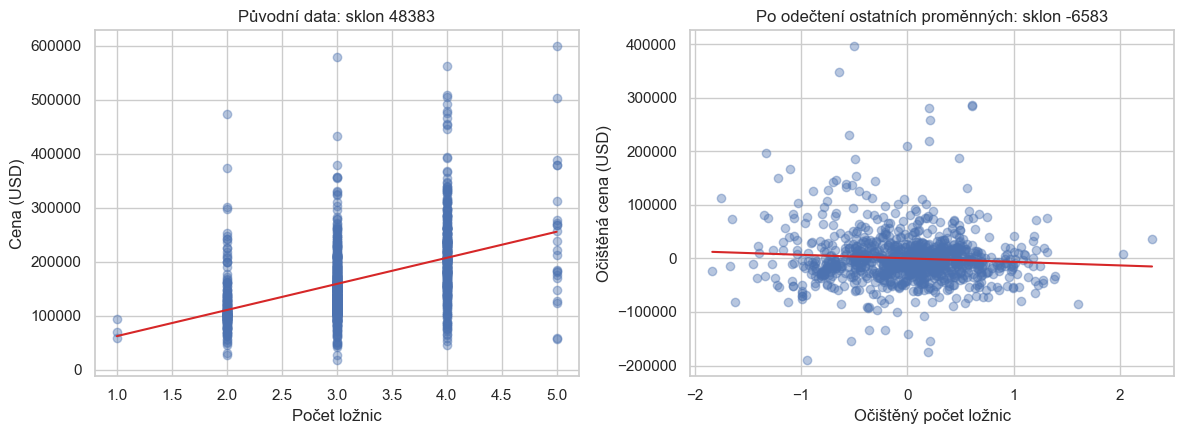

In [16]:
# 1) Prostá regrese price ~ bedrooms a koeficient u bedrooms v modelu z Úkolu 01
simple = smf.ols('price ~ bedrooms', data=houses).fit()   
j = cols.index('bedrooms')                                       
print(f'Sklon prosté regrese                      = {simple.params["bedrooms"]:9.1f} USD / ložnici')
print(f'Koeficient bedrooms ve vícenásobném modelu = {beta_hat[j]:9.1f} USD / ložnici')

# 2) Frisch–Waugh–Lovell 
def residual_maker(Z):
    """Rezidua projekce na sloupce Z, jako funkce."""
    Q_z, _ = np.linalg.qr(Z)
    return lambda v: v - Q_z @ (Q_z.T @ v)


other = [i for i in range(p) if i != j]                           # všechny sloupce kromě bedrooms (včetně interceptu)
M_other = residual_maker(X[:, other])
x_tilde, y_tilde = M_other(X[:, j]), M_other(y)                   # M_{-j} x_j  a  M_{-j} y
slope_fwl = (x_tilde @ y_tilde) / (x_tilde @ x_tilde)            # sklon y_tilde na x_tilde (přes počátek)
print(f'\nFWL sklon = {slope_fwl:.4f},  koeficient z vícenásobného modelu = {beta_hat[j]:.4f}')

# 3) R² pomocné regrese bedrooms ~ ostatní sloupce:  R² = 1 - SSE/SST
aux_r2 = 1 - (x_tilde @ x_tilde) / np.sum((X[:, j] - X[:, j].mean()) ** 2)
print(f'R² pomocné regrese (bedrooms ~ ostatní) = {aux_r2:.3f}')

# 4) Dva grafy: surová data a data očištěná od ostatních sloupců
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
xs = np.sort(X[:, j])
axes[0].scatter(X[:, j], y, alpha=0.4)
axes[0].plot(xs, simple.params['Intercept'] + simple.params['bedrooms'] * xs, color='tab:red')
axes[0].set(title=f'Původní data: sklon {simple.params["bedrooms"]:.0f}', xlabel='Počet ložnic', ylabel='Cena (USD)')
axes[1].scatter(x_tilde, y_tilde, alpha=0.4)
axes[1].plot(np.sort(x_tilde), slope_fwl * np.sort(x_tilde), color='tab:red')
axes[1].set(title=f'Po odečtení ostatních proměnných: sklon {slope_fwl:.0f}',
            xlabel='Očištěný počet ložnic', ylabel='Očištěná cena (USD)')
plt.tight_layout()
plt.show()

### Odpověď
**1.** Prostá regrese dává sklon **+48 383 USD za ložnici**, vícenásobná **−6 583 USD** (t = −2,39; p = 0,017). Regrese M₋ⱼy na M₋ⱼxⱼ dává přesně −6 583, FWL tedy platí. Pokud by ložnice nebyly s ničím korelované, oba sklony by byly stejné

**2.** Levý graf ukazuje kladný vztah v surových datech, pravý ukazuje očištěná data se zápornou přímkou.

**3.** Ostatní regresory vysvětlují **45,7 %** variability počtu ložnic, hlavně plocha (korelace 0,66). Zbylých asi 54 % je „vlastní“ informace o ložnicích, ze které se koeficient odhaduje.

**4.** Dům s více ložnicemi bývá větší a to je to, co zvyšuje cenu – proto jsou v prosté regresi ložnice „dražší“. Koeficient $-6\,600$ USD říká: porovnáme-li dva domy se **stejnou** obytnou plochou, počtem koupelen, stářím a krbem, má ten s o jednu ložnici víc v průměru cenu o zhruba 6 600 USD nižší. Stejná plocha rozdělená do více menších pokojů znamená menší pokoje (méně luxusu).

## Task 05 - Dummy variables and the trap
1. Add the column `no_fireplace = 1 - fireplace` to the model matrix of Task 01 (keeping the intercept). What is the rank? Fit the model with `sm.OLS(y, X).fit()` and with your `my_ols`. Which coefficients are identified (i.e. are the same for every solution of the normal equations)? Express them through the output. What would R's `lm` report?
2. Now remove the intercept and keep **both** dummies. What is the rank now? Show that this model has exactly the same fitted values as the model of Task 01 and explain why with the column space $\mathcal{M}(\mathbf{X})$. How are the coefficients of the two parametrisations related?
3. Compare the `R-squared` reported by `statsmodels` for the model in 2. with Task 01. In Exercise 03 the model through the origin reported the uncentred $R^2 = \sum_i \widehat{y}_i^2 / \sum_i y_i^2$. Is that the case here? Explain why not (hint: is the vector $\mathbf{1}$ in $\mathcal{M}(\mathbf{X})$?) and what really decides whether a model "has an intercept".

In [17]:
i_fire = cols.index('fireplace[T.True]')
no_fireplace = 1 - X[:, i_fire]
X_trap = np.column_stack([X, no_fireplace])
model_trap = sm.OLS(y, X_trap).fit()
beta_trap, y_trap, e_trap, s2_trap, h_trap = my_ols(X_trap, y)
X_no_intercept = np.column_stack([X[:, 2:], no_fireplace, X[:, i_fire]])
model_no_intercept = sm.OLS(y, X_no_intercept).fit()
r2_uncentered = 1 - np.sum((y - model_no_intercept.fittedvalues)**2) / (y @ y)
assert np.allclose(model_no_intercept.fittedvalues, model.fittedvalues, atol=1e-6)

cols_trap = list(cols) + ['no_fireplace']

print('1) Model s interceptem a oběma indikátory (past dummy proměnných)\n')
print('Hodnost matice (sloupec 1 = fireplace + no_fireplace, proto je jeden sloupec zbytečný):')
display(pd.DataFrame({'počet sloupců': [X_trap.shape[1]], 'hodnost': [np.linalg.matrix_rank(X_trap)]},
                     index=['X s oběma indikátory']))

print('Koeficienty dvou různých řešení (jednotlivě nejsou určeny, každý program vybere jiné):')
display(pd.DataFrame({'statsmodels (nejmenší norma)': model_trap.params,
                      'my_ols (no_fireplace = 0)': beta_trap}, index=cols_trap).round(2))
print('Sklony living_area, bathrooms, bedrooms a age vyšly v obou řešeních stejně, jsou tedy určeny.\n')

print('Kombinace koeficientů, které jsou určeny (v obou řešeních vyjdou stejně):')
display(pd.DataFrame({'statsmodels': [model_trap.params[0] + model_trap.params[-1],
                                      model_trap.params[0] + model_trap.params[i_fire],
                                      model_trap.params[i_fire] - model_trap.params[-1]],
                      'my_ols': [beta_trap[0] + beta_trap[-1],
                                 beta_trap[0] + beta_trap[i_fire],
                                 beta_trap[i_fire] - beta_trap[-1]]},
                     index=['intercept + no_fireplace (dům bez krbu)',
                            'intercept + fireplace (dům s krbem)',
                            'fireplace - no_fireplace (rozdíl krb vs. bez krbu)']).round(2))

print('2) Model bez interceptu, oba indikátory (fireplace i no_fireplace)\n')
print('Hodnost matice (plná, řešení je jednoznačné) a shoda predikcí s modelem z Úkolu 01:')
display(pd.DataFrame({'počet sloupců': [X_no_intercept.shape[1]],
                      'hodnost': [np.linalg.matrix_rank(X_no_intercept)],
                      'max. rozdíl predikcí': [np.max(np.abs(model_no_intercept.fittedvalues - model.fittedvalues))]},
                     index=['X bez interceptu']))

print('Koeficienty obou parametrizací (nový model = úrovně skupin, starý = úroveň + rozdíl):')
display(pd.DataFrame({'model bez interceptu': [model_no_intercept.params[4], model_no_intercept.params[5]],
                      'model z Úkolu 01': [model.params[0], model.params[0] + model.params[i_fire]]},
                     index=['bez krbu (no_fireplace  vs.  intercept)',
                            's krbem (fireplace  vs.  intercept + fireplace)']).round(2))

print('3) R² modelu bez interceptu\n')
display(pd.DataFrame({'hodnota': [model_no_intercept.model.k_constant, model_no_intercept.rsquared, r2_uncentered]},
                     index=['k_constant (statsmodels našel v M(X) konstantu)',
                            'R² hlášené statsmodels (centrované)',
                            'R² necentrované (jako model přes počátek)']))

1) Model s interceptem a oběma indikátory (past dummy proměnných)

Hodnost matice (sloupec 1 = fireplace + no_fireplace, proto je jeden sloupec zbytečný):


C:\Users\grund\AppData\Local\Temp\ipykernel_32808\1256626278.py:4: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  model_trap = sm.OLS(y, X_trap).fit()


,počet sloupců,hodnost
X s oběma indikátory,7,6


Koeficienty dvou různých řešení (jednotlivě nejsou určeny, každý program vybere jiné):


,statsmodels (nejmenší norma),my_ols (no_fireplace = 0)
Intercept,12838.65,15313.40
fireplace[T.True],10363.91,7889.16
living_area,74.84,74.84
bathrooms,18945.19,18945.19
bedrooms,-6582.79,-6582.79
age,-141.11,-141.11
no_fireplace,2474.75,0.00


Sklony living_area, bathrooms, bedrooms a age vyšly v obou řešeních stejně, jsou tedy určeny.

Kombinace koeficientů, které jsou určeny (v obou řešeních vyjdou stejně):


... (3 outputs left out)

Koeficienty obou parametrizací (nový model = úrovně skupin, starý = úroveň + rozdíl):


,model bez interceptu,model z Úkolu 01
bez krbu (no_fireplace vs. intercept),15313.40,15313.40
s krbem (fireplace vs. intercept + fireplace),23202.56,23202.56


3) R² modelu bez interceptu



,hodnota
k_constant (statsmodels našel v M(X) konstantu),1.000000
R² hlášené statsmodels (centrované),0.603237
R² necentrované (jako model přes počátek),0.930863


### Odpověď
**1.** Platí **1 = fireplace + no_fireplace**, proto je hodnost **6, ne 7**, a normální rovnice mají nekonečně mnoho řešení. Identifikované jsou koeficienty plochy, koupelen, ložnic a věku, které jsou ve všech řešeních stejné, a kombinace **b₀ + b_no = 15 313** a **b_fire − b_no = 7 889**. Jednotlivé b₀, b_fire a b_no identifikované nejsou: `statsmodels` vrací řešení s nejmenší normou (12 839; 10 364; 2 475), `my_ols` řešení s b_no = 0 (15 313; 7 889; 0). Obě dávají stejné ŷ. R `lm` by poslední závislý koeficient (`no_fireplace`) označil jako `NA`, tedy stejně jako `my_ols`.

**2.** Bez interceptu a s oběma indikátory je hodnost **6** a predikce se od úlohy 01 liší jen o 1,5 × 10⁻⁸ USD. Sloupcový prostor je stejný: 1 = fireplace + no_fireplace a fireplace už v prostoru je, takže M(X) se nezměnil a nezměnila se ani projekce. Koeficienty souvisí takto: **b_no = b₀ = 15 313** a **b_fire(nový) = b₀ + b_fire = 23 203**; ostatní zůstávají. Nové koeficienty jsou tedy úrovně obou skupin, staré jsou úroveň a rozdíl.

**3.** `statsmodels` hlásí stejné **R² = 0,6032**, ne necentrované 0,931 jako u modelu počátkem ve cvičení 03. Vektor 1 totiž leží v M(X), `statsmodels` to zjistí z hodnosti (`k_constant = 1`) a použije centrovaný součet čtverců. O tom, zda má model intercept, nerozhoduje přítomnost sloupce s názvem intercept, ale to, **zda 1 ∈ M(X)**.

## Task 06 - Leverage as a data check
Plot the leverages $h_{ii}$ of the model of Task 01 against the observation index and list the ten houses with the largest $h_{ii}$. Compare with the mean leverage $(m+1)/n$.

1. What do the houses with the largest leverage have in common? Look at the variable `age` in particular: how many houses are older than 100 and older than 200 years, and how do they differ from the rest in the other variables? Are such values plausible, and what would you check or ask before using them?
2. Refit the model without the houses with `age` above 150 years and compare the coefficients, in particular the coefficient of `age`. Does the decision matter?
3. Leverage depends only on $\mathbf{X}$. Why is it nevertheless a good tool for finding errors in the data, before the response is even used?

průměrná leverage (m+1)/n = 0.0057,  práh 3(m+1)/n = 0.0171,  domů nad prahem: 25


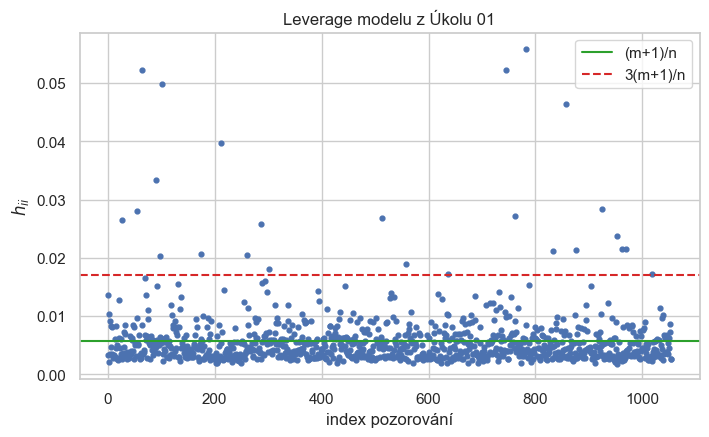

,price,living_area,bathrooms,bedrooms,age,fireplace,h_ii
783,88092.0,3944,1.0,4,185,True,0.055933
745,599701.0,5114,4.5,5,131,True,0.052303
65,226742.0,1989,2.0,3,247,True,0.052240
102,59003.0,3285,2.0,5,233,False,0.049844
857,75975.0,1300,2.0,3,227,True,0.046357
211,562546.0,5228,4.0,4,14,True,0.039726
91,185318.0,1500,1.5,4,208,True,0.033288
925,139627.0,1980,1.0,4,205,False,0.028452
54,157513.0,2164,2.0,3,183,True,0.028049
762,139104.0,1760,3.0,4,135,False,0.027108


domů starších než 100 let: 71
domů starších než 150 let: 15
domů starších než 200 let: 5


,price,living_area,bathrooms,bedrooms,fireplace,počet
age,,,,,,
age <= 100,171443.604675,1835.568089,1.967480,3.184959,0.618902,984
age > 100,115636.788732,1582.746479,1.373239,3.183099,0.253521,71


,všechny domy,age <= 150,změna v %,"se, všechny","se, age <= 150","t, všechny","t, age <= 150"
Intercept,15313.400534,12112.228288,-20.904385,7322.384487,7399.716598,2.091313,1.636850
fireplace[T.True],7889.161957,7098.789522,-10.018459,3538.811180,3527.769269,2.229325,2.012260
living_area,74.840807,79.754259,6.565205,3.928547,3.980519,19.050508,20.036144
bathrooms,18945.193811,17321.725937,-8.569286,3689.778429,3716.926913,5.134507,4.660228
bedrooms,-6582.792908,-7813.961961,18.702837,2749.804550,2754.864487,-2.393913,-2.836423
age,-141.106232,-56.862658,-59.702235,48.477711,59.559416,-2.910745,-0.954722


R²: 0.6032 -> 0.6141
max |h_ii - (1/n + d_i^2/(n-1))| = 1.0e-15


In [18]:
# 1) Leverage h_ii z Úkolu 02 (závisí jen na X, ne na ceně) proti indexu pozorování
h_mean, h_3 = p / n, 3 * p / n                                    # průměr (m+1)/n a práh 3(m+1)/n z poznámek
print(f'průměrná leverage (m+1)/n = {h_mean:.4f},  práh 3(m+1)/n = {h_3:.4f},  domů nad prahem: {(h > h_3).sum()}')

plt.figure(figsize=(8, 4.5))
plt.scatter(np.arange(n), h, s=12)
plt.axhline(h_mean, color='tab:green', label='(m+1)/n')
plt.axhline(h_3, color='tab:red', ls='--', label='3(m+1)/n')
plt.xlabel('index pozorování'); plt.ylabel('$h_{ii}$'); plt.legend()
plt.title('Leverage modelu z Úkolu 01')
plt.show()

top = np.argsort(h)[::-1][:10]                                    # indexy deseti největších h_ii
display(houses.loc[top, ['price', 'living_area', 'bathrooms', 'bedrooms', 'age', 'fireplace']].assign(h_ii=h[top]))

# 2) Staré domy: kolik jich je a čím se liší od ostatních
for limit in (100, 150, 200):
    print(f'domů starších než {limit} let: {(houses["age"] > limit).sum()}')
old = houses['age'] > 100
group_means = (houses[['price', 'living_area', 'bathrooms', 'bedrooms', 'fireplace']].astype(float)
               .groupby(old).mean().rename(index={False: 'age <= 100', True: 'age > 100'}))
display(group_means.assign(počet=old.groupby(old).size().to_numpy()))

# 3) Model bez domů starších než 150 let
keep = (houses['age'] <= 150).to_numpy()
fit_all, fit_trim = sm.OLS(y, X).fit(), sm.OLS(y[keep], X[keep]).fit()
display(pd.DataFrame({'všechny domy': fit_all.params, 'age <= 150': fit_trim.params,
                      'změna v %': 100 * (fit_trim.params / fit_all.params - 1),
                      'se, všechny': fit_all.bse, 'se, age <= 150': fit_trim.bse,
                      't, všechny': fit_all.tvalues, 't, age <= 150': fit_trim.tvalues}, index=cols))
print(f'R²: {fit_all.rsquared:.4f} -> {fit_trim.rsquared:.4f}')

# 4) Kontrola: leverage = 1/n + d_i^2/(n-1), kde d_i je Mahalanobisova vzdálenost od těžiště regresorů
Z_c = X[:, 1:] - X[:, 1:].mean(axis=0)                            # centrované regresory (bez interceptu)
d2 = np.sum(Z_c * np.linalg.solve(np.cov(X[:, 1:], rowvar=False), Z_c.T).T, axis=1)
print(f'max |h_ii - (1/n + d_i^2/(n-1))| = {np.abs(h - (1 / n + d2 / (n - 1))).max():.1e}')

### Odpověď
Průměrná leverage je $(m+1)/n = 6/1055 = 0{,}0057$; označuje se za velkou $h_{ii} > 3(m+1)/n = 0{,}0171$, což splňuje **25 domů**. Největší hodnota je 0,0559, tedy téměř desetkrát víc než průměr. 

**1.** Devět z deseti domů s nejvyšší leverage je starších než 130 let; zbývající má největší plochu v datech (5 228 ft²) a dům s plochou 5 114 ft² je v první desítce i díky věku 131 let. Starších než 100 let je **71** domů, starších než 200 let **5**. Domy nad 100 let jsou proti zbytku levnější (116 tis. oproti 171 tis. USD), menší (1 583 oproti 1 836 ft²), s méně koupelnami (1,37 oproti 1,97) a řidčeji s krbem (25 % oproti 62 %), ložnic mají stejně (3,18). Pět domů nad 200 let je naopak spíš větších (2 011 ft², 3,8 ložnice), ale z pěti domů nelze nic zobecňovat. Takové hodnoty jsou možné, ale v USA vzácné (věk až 247 let). Ověřil bych zdroj, jestli jde o stáří stavby, nebo její nejstarší části, a jestli nejde o překlep či chybný rok.

**2.** Po vyřazení 15 domů nad 150 let klesne koeficient věku z **−141 (SE 48; p = 0,004) na −57 USD za rok (SE 60; p = 0,34)**, tedy o 60 % a přestane být významný. Ostatní koeficienty se mění méně: ložnice o 19 %, intercept o 21 %, ostatní do 10 %. **Rozhodnutí tedy záleží**, a to hlavně pro závěr o věku: 15 domů z 1 055 nese velkou část jeho efektu.

**3.** Platí hᵢᵢ = 1/n + dᵢ²/(n − 1), kde dᵢ je Mahalanobisova vzdálenost od těžiště prediktorů (ověřeno numericky). Leverage tedy měří, jak neobvyklá je kombinace hodnot v prostoru X, a překlep v prediktoru se projeví bez ohledu na cenu. Zároveň ŷᵢ = Σⱼhᵢⱼyⱼ a var(êᵢ) = σ²(1 − hᵢᵢ), takže bod s vysokou leverage přitahuje přímku k sobě a jeho reziduum bývá malé: po prohlídce reziduí by se chyba nemusela vůbec ukázat. Vysoká leverage sama chybu nedokazuje, jen říká, kde se dívat.

## Task 07 - When the default fails: polynomials in the living area
Fit polynomial models `price` $= \beta_0 + \beta_1 a + \beta_2 a^2 + \dots + \beta_d a^d + e$ in the living area $a$ (square feet, raw) for degrees $d = 1, \dots, 6$, building the columns $a^k$ yourself (`np.vander`). For each degree record in one table:
- $\kappa(\mathbf{X})$ and `np.linalg.matrix_rank(X)`,
- $R^2$ and `df_model` from `sm.OLS(y, X).fit()` (default, pseudoinverse),
- $R^2$ from `sm.OLS(y, X).fit(method='qr')` and from your `my_ols`,
- $R^2$ with the standardized variable $(a - \overline{a})/s_a$ instead of $a$.

1. The models are **nested**: the model of degree $d+1$ contains the model of degree $d$. What does that imply for $R^2$ as $d$ grows (think of the projection onto a larger subspace)? Which column of the table violates this, and from which degree on?
2. Explain what the default method does wrong. Hint: compute the singular values of $\mathbf{X}$, compare them with the tolerance used to decide which ones count as zero (`np.linalg.matrix_rank` uses $s_1 \cdot \max(n, p) \cdot \varepsilon_{\text{machine}}$), and look at `df_model`.
3. Why do QR and the standardized version give the correct answer? Which fix would you use in practice?

In [19]:
a = houses['living_area'].to_numpy(dtype=float)
z = (a - a.mean()) / a.std(ddof=1)
rows = []
ss_total = np.sum((y - y.mean())**2)
for degree in range(1, 7):
    Xp = np.vander(a, N=degree+1, increasing=True)
    Xz = np.vander(z, N=degree+1, increasing=True)
    default_fit = sm.OLS(y, Xp).fit()
    qr_fit = sm.OLS(y, Xp).fit(method='qr')
    beta_qr, pred_qr, resid_qr, s2_qr, h_qr = my_ols(Xp, y)
    std_fit = sm.OLS(y, Xz).fit()
    sv = np.linalg.svd(Xp, compute_uv=False)
    tol = sv[0] * max(Xp.shape) * np.finfo(float).eps
    # Výchozí metoda je pinv: zahodí směry se s_k < 1e-15 * s_1 a promítá na zbylé levé singulární vektory.
    U_sv = np.linalg.svd(Xp, full_matrices=False)[0]
    kept = int(np.sum(sv > 1e-15 * sv[0]))
    resid_trunc = y - U_sv[:, :kept] @ (U_sv[:, :kept].T @ y)
    rows.append({'stupeň': degree, 'kappa(X)': np.linalg.cond(Xp),
        'rank(X)': np.linalg.matrix_rank(Xp), 'df_model default': default_fit.df_model,
        'R2 default': default_fit.rsquared, 'R2 QR': qr_fit.rsquared,
        'R2 my_ols': 1 - resid_qr@resid_qr/ss_total, 'R2 standardizováno': std_fit.rsquared,
        'kappa(std)': np.linalg.cond(Xz), 'rank(std)': np.linalg.matrix_rank(Xz),
        'pinv směrů': kept, 'R2 ruční ořez': 1 - resid_trunc@resid_trunc/ss_total,
        's_min': sv[-1], 'tolerance': tol})
    print(f'stupeň {degree}: singular values={sv}, tolerance={tol:.4g}')
polynomial_results = pd.DataFrame(rows).set_index('stupeň')
print(polynomial_results.to_string(float_format=lambda value: f'{value:.6g}'))
print('Stupeň 6, max. rozdíl predikcí my_ols a standardizované verze:', np.max(np.abs(pred_qr - std_fit.fittedvalues)))

stupeň 1: singular values=[6.28634292e+04 1.11151559e+01], tolerance=1.473e-08
stupeň 2: singular values=[1.53956768e+08 2.02412054e+04 4.81270039e+00], tolerance=3.607e-05
stupeň 3: singular values=[4.61292348e+11 4.58730356e+07 8.81539911e+03 2.40506467e+00], tolerance=0.1081
stupeň 4: singular values=[1.64438024e+15 1.28449038e+11 1.80220170e+07 3.78555732e+03
 1.07672771e+00], tolerance=385.2
stupeň 5: singular values=[6.77411450e+18 4.05911228e+14 3.94738567e+10 6.41867768e+06
 1.32927270e+03 6.61431069e-01], tolerance=1.587e+06
stupeň 6: singular values=[3.09353578e+22 1.34481682e+18 9.37098906e+13 1.20458400e+10
 2.58389135e+06 2.34477854e+05 1.90101944e-01], tolerance=7.247e+09
          kappa(X)  rank(X)  df_model default  R2 default    R2 QR  R2 my_ols  R2 standardizováno  kappa(std)  rank(std)  pinv směrů  R2 ruční ořez    s_min   tolerance
stupeň                                                                                                                                  

C:\Users\grund\AppData\Local\Temp\ipykernel_32808\1447066162.py:8: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  default_fit = sm.OLS(y, Xp).fit()
C:\Users\grund\AppData\Local\Temp\ipykernel_32808\1447066162.py:8: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  default_fit = sm.OLS(y, Xp).fit()
C:\Users\grund\AppData\Local\Temp\ipykernel_32808\1447066162.py:8: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  default_fit = sm.OLS(y, Xp).fit()


### Odpověď
**1.** Modely jsou vnořené, M(X_d) ⊂ M(X_{d+1}), a projekce na větší podprostor nemůže zvětšit reziduální součet čtverců. **R² tedy nesmí s d klesat.** Porušuje to sloupec `R2 default` od **stupně 4**: 0,5831 → 0,5802 → 0,5652 → 0,5111. Správně je 0,5831 → 0,5878 → 0,5879 → 0,5880 (QR, `my_ols` i standardizovaně).

**2.** X má ve skutečnosti plnou hodnost, ale singulární čísla se liší o mnoho řádů: u stupně 6 je s₁ ≈ 3,1 × 10²², s₇ ≈ 0,19 a κ ≈ 1,6 × 10²³. Tolerance je relativní k s₁, takže malá, ale nenulová čísla (0,19 je pod tolerancí 7,2 × 10⁹) jsou prohlášena za nulu. Od stupně 4 tak `matrix_rank` hlásí 4 a `df_model` zůstává 3. Výchozí metoda je pseudoinverze, která tyto směry zahodí a **promítá na podprostor prvních čtyř levých singulárních vektorů**. Ten není M(X_d) a neobsahuje ani M(X_{d−1}), proto argument o vnoření neplatí. Ruční ořez SVD (sloupec `R2 ruční ořez`, práh 10⁻¹⁵ s₁) dá přesně stejná R² jako `R2 default`, takže příčina je potvrzená. Metoda navíc neohlásí chybu, jen varování.

**3.** QR ortogonalizuje sloupce postupně a žádný směr nezahazuje, takže Q opravdu generuje M(X_d) i při špatném měřítku. Predikce `my_ols` a standardizované verze se u stupně 6 liší jen o 10⁻⁷ USD. Standardizace řeší příčinu: κ klesne z 1,6 × 10²³ na 3,2 × 10³ a hodnost je plná, takže funguje i pseudoinverze. V praxi bych **plochu centroval a škáloval** (případně použil ortogonální polynomy) a řešil QR. Samotné QR na surových mocninách dá správné predikce, ale při κ > 1/ε nelze věřit jednotlivým koeficientům. Věcně navíc stupně nad 2 přidají k R² dohromady jen asi 0,005.

## Task 08 - Singular values and the variance of the estimates
Take the model of Task 01 with all non-intercept columns standardized (including `fireplace`), so that the coefficients are comparable.

1. Compute the SVD $\mathbf{X} = \mathbf{P}\mathbf{S}\mathbf{Q}^T$, the singular values and $\kappa(\mathbf{X})$. Is there a problem with collinearity in this model?
2. `statsmodels` reports the standard errors $\sqrt{s_n^2\,[(\mathbf{X}^T\mathbf{X})^{-1}]_{jj}}$ (Theorem 3.4 will justify this in the next lecture). Using the SVD, write $[(\mathbf{X}^T\mathbf{X})^{-1}]_{jj} = \sum_k q_{jk}^2/s_k^2$ and compute the standard errors from this formula; compare with `model.bse`.
3. For the coefficient of `bedrooms`, compute the share of each term $q_{jk}^2/s_k^2$ in the sum. Which singular direction contributes most? Which variables have large weights in that direction $\mathbf{q}_k$, and how does it relate to Task 04?

In [20]:
X_std = X.astype(float).copy()
X_std[:, 1:] = (X_std[:, 1:] - X_std[:, 1:].mean(axis=0)) / X_std[:, 1:].std(axis=0, ddof=1)
model_std = sm.OLS(y, X_std).fit()
P, singular_values, Vt = np.linalg.svd(X_std, full_matrices=False)
kappa_std = singular_values[0] / singular_values[-1]
V = Vt.T
cov_unscaled = (V / singular_values**2) @ Vt
se_svd = np.sqrt(model_std.scale * np.diag(cov_unscaled))
print('Singulární čísla a kappa:', singular_values, kappa_std)
print('Směrodatné chyby SVD / statsmodels:\n', np.column_stack([se_svd, model_std.bse]))
assert np.allclose(se_svd, model_std.bse, rtol=1e-8)
j = cols.index('bedrooms')
terms = V[j, :]**2 / singular_values**2
shares = terms / terms.sum()
svd_shares = pd.DataFrame({'singulární směr k': np.arange(1, len(shares)+1), 'podíl': shares}).set_index('singulární směr k')
k = int(np.argmax(shares))
print('Podíl každého směru pro rozptyl bedrooms:\n', svd_shares)
print('Dominantní směr a jeho váhy:', k+1, dict(zip(cols, V[:, k])))
print('Pravé singulární vektory q_k (sloupce):\n', pd.DataFrame(V, index=cols,
      columns=np.arange(1, len(shares)+1)).round(3))
print('sqrt(n):', np.sqrt(len(y)))
print('VIF z úlohy 04 / (n-1) * součet členů:', 1/(1-aux_r2), (len(y)-1)*terms.sum())

Singulární čísla a kappa: [53.73999861 32.48076354 32.26768325 26.7009766  19.86457394 15.27303891] 3.518618588253413
Směrodatné chyby SVD / statsmodels:
 [[1498.11666352 1498.11666352]
 [1738.46723643 1738.46723643]
 [2603.14880031 2603.14880031]
 [2399.40016612 2399.40016612]
 [2034.47976389 2034.47976389]
 [1694.50296653 1694.50296653]]
Podíl každého směru pro rozptyl bedrooms:
                       podíl
singulární směr k          
1                  0.038346
2                  0.000000
3                  0.140127
4                  0.057572
5                  0.596025
6                  0.167930
Dominantní směr a jeho váhy: 5 {'Intercept': np.float64(-0.0), 'fireplace[T.True]': np.float64(-0.16695002824014488), 'living_area': np.float64(0.255819236312832), 'bathrooms': np.float64(0.5968548287461496), 'bedrooms': np.float64(-0.6411992730343667), 'age': np.float64(0.373245243861912)}
Pravé singulární vektory q_k (sloupce):
                        1    2      3      4      5      6


### Odpověď
**1.** Singulární čísla jsou **53,74; 32,48; 32,27; 26,70; 19,86; 15,27** a **κ(X) ≈ 3,52**, takže kolinearita tu vážný problém není (surová matice má κ ≈ 9 881, což je hlavně důsledek měřítek). Druhé číslo je přesně √n = 32,48 a jeho směr je čistě intercept, protože standardizované sloupce jsou ortogonální k 1.

**2.** Směrodatné chyby ze vzorce Σₖqⱼₖ²/sₖ² souhlasí s `model.bse` (například u `bedrooms` 2 034 USD na jednu směrodatnou odchylku).

**3.** U `bedrooms` tvoří největší podíl rozptylu, **59,6 %, pátý směr** (s₅ = 19,86), dalších 16,8 % šestý s nejmenším s₆. Pátý směr má váhy ložnice −0,64, koupelny +0,60, věk +0,37, plocha +0,26, krb −0,17: je to hlavně **kontrast více koupelen, méně ložnic**. Ložnice mají v tomto směru velkou váhu a s₅ je malé, a člen qⱼₖ²/sₖ² je proto velký: dat, kde se ložnice mění nezávisle na koupelnách a ploše, je málo. To je stejná informace jako v úloze 04: zbývá jen „očištěná“ variabilita ložnic. Numericky platí (n − 1)Σₖqⱼₖ²/sₖ² = 1/(1 − R²ₐᵤₓ) = **1,84** (VIF), takže korelace s ostatními regresory zvětšuje směrodatnou chybu asi 1,36krát. To je znatelné, ale ne dramatické.

## Task 09 - Theorem 3.4 by simulation
Take the model of Task 01 as the truth: the model matrix $\mathbf{X}$ is fixed (the 1055 houses), the true parameters are $\boldsymbol{\beta} = \widehat{\boldsymbol{\beta}}$ and $\sigma = s_n$ from Task 01. Generate at least 2000 new response vectors $\mathbf{y}^* = \mathbf{X}\boldsymbol{\beta} + \mathbf{e}^*$, $\mathbf{e}^* \sim N_n(\mathbf{0}, \sigma^2\mathbf{I}_n)$, and in each replication compute $\widehat{\boldsymbol{\beta}}^*$ and $s_n^{2*}$ (use your `my_ols`).

1. Compare the mean of $\widehat{\boldsymbol{\beta}}^*$ with $\boldsymbol{\beta}$ and the mean of $s_n^{2*}$ with $\sigma^2$ (Theorem 3.4, points 1 and 3).
2. Compare the empirical covariance matrix of $\widehat{\boldsymbol{\beta}}^*$ with $\sigma^2(\mathbf{X}^T\mathbf{X})^{-1}$: the standard deviations of the coefficients and the correlation matrix.
3. The estimates of the coefficients of `bedrooms` and `living_area` are correlated. Which sign does the correlation have, and why? Draw the scatter plot of the two estimates and relate it to the correlation of the regressors and to Task 04.
4. For `bedrooms`, check that $T = (\widehat{\beta}_j^* - \beta_j)/\big(s_n^*\sqrt{[(\mathbf{X}^T\mathbf{X})^{-1}]_{jj}}\big)$ has the $t(n-m-1)$ distribution (Theorem 3.5): histogram with the density, and the share of replications in which the 95 % confidence interval covers the true $\beta_j$.

Průměr beta* minus beta: [ 3.78147115e+02  2.29609234e+01  1.34156884e-02 -1.64279783e+02
 -1.85268274e+01 -2.37119451e+00]
Průměr s_n^2* / sigma^2: 2367359493.9276967 2367792982.076923
Empirické / teoretické SD:
 [[7.27511044e+03 7.32238449e+03]
 [3.52430510e+03 3.53881118e+03]
 [4.02091936e+00 3.92854654e+00]
 [3.72376480e+03 3.68977843e+03]
 [2.74332514e+03 2.74980455e+03]
 [4.92442703e+01 4.84777111e+01]]
Korelační matice odhadů:
 [[ 1.          0.03139534  0.17778685 -0.37707834 -0.58740708 -0.35000399]
 [ 0.03139534  1.         -0.25428436 -0.12023342  0.03001322  0.06056394]
 [ 0.17778685 -0.25428436  1.         -0.5269178  -0.48919438 -0.01495314]
 [-0.37707834 -0.12023342 -0.5269178   1.         -0.09638037  0.36734915]
 [-0.58740708  0.03001322 -0.48919438 -0.09638037  1.         -0.1712312 ]
 [-0.35000399  0.06056394 -0.01495314  0.36734915 -0.1712312   1.        ]]
Korelace prediktorů bedrooms a living_area: 0.663006885314016
Korelace odhadů bedrooms a living_area: -0.48919

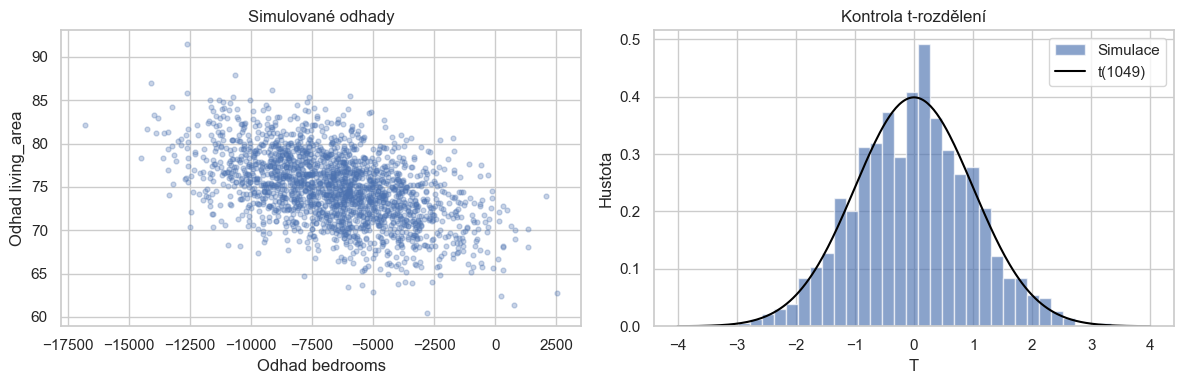

In [21]:
i_bed = cols.index('bedrooms')
rng = np.random.default_rng(20261031)
repetitions = 2000
sigma = np.sqrt(model.scale)
Qsim, Rsim = np.linalg.qr(X, mode='reduced')
Rinv = sla.solve_triangular(Rsim, np.eye(Rsim.shape[0]))
xtx_inv = Rinv @ Rinv.T
cov_theory = sigma**2 * xtx_inv
beta_sim = np.empty((repetitions, X.shape[1])); s2_sim = np.empty(repetitions)
for i in range(repetitions):
    y_star = X @ model.params + rng.normal(0, sigma, size=len(y))
    beta_sim[i], _, _, s2_sim[i], _ = my_ols(X, y_star)
print('Průměr beta* minus beta:', beta_sim.mean(axis=0) - model.params)
print('Průměr s_n^2* / sigma^2:', s2_sim.mean(), model.scale)
print('Empirické / teoretické SD:\n', np.column_stack([beta_sim.std(axis=0, ddof=1),
                                                        np.sqrt(np.diag(cov_theory))]))
print('Korelační matice odhadů:\n', np.corrcoef(beta_sim, rowvar=False))
print('Korelace prediktorů bedrooms a living_area:',
      np.corrcoef(houses.bedrooms, houses.living_area)[0, 1])
print('Korelace odhadů bedrooms a living_area:', np.corrcoef(beta_sim[:, i_bed], beta_sim[:, i_area])[0, 1])
j = cols.index('bedrooms')
t_values = (beta_sim[:, j] - model.params[j]) / (np.sqrt(s2_sim) * np.sqrt(xtx_inv[j, j]))
df_t = len(y) - X.shape[1]
critical = stats.t.ppf(.975, df_t)
coverage = np.mean(np.abs(beta_sim[:, j] - model.params[j]) <= critical*np.sqrt(s2_sim*xtx_inv[j, j]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(beta_sim[:, i_bed], beta_sim[:, i_area], alpha=.3, s=12)
axes[0].set(xlabel='Odhad bedrooms', ylabel='Odhad living_area', title='Simulované odhady')
axes[1].hist(t_values, bins=35, density=True, alpha=.65, label='Simulace')
t_grid = np.linspace(-4, 4, 300)
axes[1].plot(t_grid, stats.t.pdf(t_grid, df_t), color='black', label=f't({df_t})')
axes[1].set(xlabel='T', ylabel='Hustota', title='Kontrola t-rozdělení'); axes[1].legend()
plt.tight_layout()
print(f'df={df_t}; pokrytí 95% intervalu={coverage:.3f}')
sd_theory = np.sqrt(np.diag(cov_theory))
corr_theory = cov_theory / np.outer(sd_theory, sd_theory)
print('Teoretická korelační matice:\n', np.round(corr_theory, 3))
print('Max. rozdíl empirické a teoretické korelace:', np.max(np.abs(np.corrcoef(beta_sim, rowvar=False) - corr_theory)))
print('Poměr empirické a teoretické SD:', np.round(beta_sim.std(axis=0, ddof=1) / sd_theory, 3))
print('z-skóry průměrů beta* (Monte Carlo chyba):', np.round((beta_sim.mean(axis=0) - model.params) / (sd_theory / np.sqrt(repetitions)), 2))
others = np.delete(X, [i_area, i_bed], axis=1)
print('Parciální korelace living_area a bedrooms:', np.corrcoef(my_ols(others, X[:, i_area])[2], my_ols(others, X[:, i_bed])[2])[0, 1])
print('T: průměr, rozptyl, KS test proti t:', t_values.mean(), t_values.var(ddof=1), stats.kstest(t_values, 't', args=(df_t,)).pvalue)

### Odpověď
**1.** Průměry β̂* jsou blízko β: odchylky jsou v jednotkách Monte Carlo chyby nejvýše |z| = 2,31 (intercept), což je u šesti korelovaných odhadů v mezích náhody. Průměr s_n²* je 2,3674 × 10⁹ proti σ² = 2,3678 × 10⁹. Obojí odpovídá nestrannosti z věty 3.4.

**2.** Empirické SD se od teoretických √(σ²[(XᵀX)⁻¹]ⱼⱼ) liší nejvýše o 2,4 % (poměry 0,99 až 1,02). Empirická a teoretická korelační matice se liší nejvýše o 0,036, což je pořádek chyby odhadu korelace ve 2 000 replikacích (přibližně 1/√2000 ≈ 0,022).

**3.** Odhady `bedrooms` a `living_area` korelují **záporně: empiricky −0,49, teoreticky −0,475**, ačkoli samotné regresory korelují kladně (**+0,66**). Korelace odhadů je přesně opačná k parciální korelaci regresorů po odečtení ostatních (+0,475): kovariance plyne z (XᵀX)⁻¹ a inverze obrací znaménko. Intuitivně: plocha a ložnice nesou zčásti stejnou informaci o ceně. Když náhoda přisoudí větší díl ploše, na ložnice zbude méně, a naopak. Souvisí to s úlohou 04, protože právě tato překrývající se část je u prosté regrese přisouzena ložnicím.

**4.** Histogram T odpovídá hustotě t s **1 049 stupni volnosti** (průměr −0,007; rozptyl 0,997; KS test p = 0,76) a 95% interval pokryl pravý koeficient v **95,0 %** replikací. Věta 3.5 se tedy potvrdila.

## Task 10 - Fireplace: interaction and separate regressions
Fit the model `price ~ living_area * fireplace` (R: `lm(price ~ living_area * fireplace)`).

1. Write the model matrix for this formula: which four columns does it have? Write the two regression lines (houses without and with a fireplace) in terms of the four coefficients and interpret each coefficient in one sentence, including its units.
2. Test whether the price per square foot is the same for houses with and without a fireplace (the $t$-test of the interaction term). State the hypotheses, the statistic, the degrees of freedom and the conclusion. Draw the data with the two fitted lines.
3. Now fit two separate simple regressions `price ~ living_area`, one for the houses with and one for the houses without a fireplace. Compare the coefficients with the lines from 1.: what is equal and why? (Think of the column space of the interaction model and of a model matrix that is block diagonal after reordering the rows.)
4. Compare $s_n$ and the standard errors of the slopes in the interaction model and in the two separate models. Which assumption about $\sigma^2$ makes the difference? Which approach would you prefer here, and what would you check to decide?

Sloupce modelové matice: ['Intercept', 'fireplace[T.True]', 'living_area', 'living_area:fireplace[T.True]']
Koeficienty:
 Intercept                        42179.745813
fireplace[T.True]               -37615.446678
living_area                         59.743304
living_area:fireplace[T.True]       31.726501
dtype: float64
Test rozdílu sklonů: t=5.239, df=1051, p=1.95e-07
Společné reziduální s_n: 49321.23571050237
SE sklonu bez/s krbu v interakčním modelu: 5.2570255857318395 3.0059754183429566
bez krbu n= 428 koeficienty= {'Intercept': 42179.745813061134, 'living_area': 59.74330386500975} s_n= 48147.107181035986 SE sklonu= 5.131878199794885
s krbem n= 627 koeficienty= {'Intercept': 4564.299134634994, 'living_area': 91.46980519857917} s_n= 50105.75658369275 SE sklonu= 3.0537895176062086
Průsečík přímek (ft²): 1185.6159707919257
Levene (rozptyl reziduí mezi skupinami): p = 0.35717862193248956
Breusch-Pagan (rozptyl závislý na regresorech): p = 7.195620605366695e-05
SD reziduí podle terčilů p

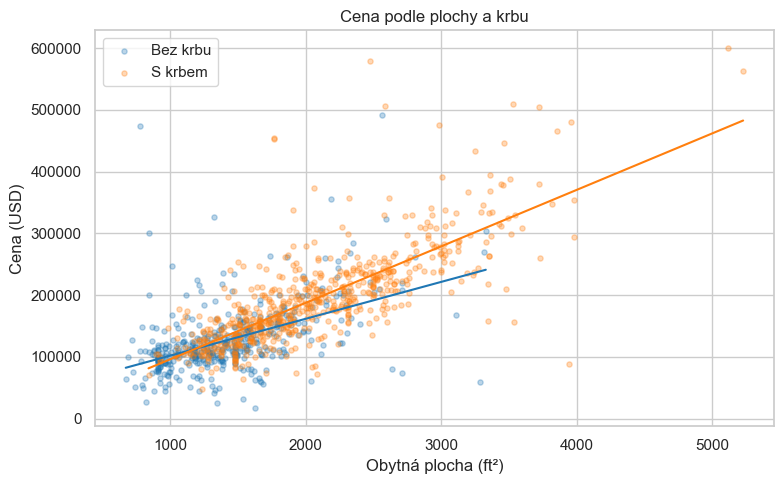

In [22]:
interaction = smf.ols('price ~ living_area * fireplace', data=houses).fit()
print('Sloupce modelové matice:', interaction.model.exog_names)
print('Koeficienty:\n', interaction.params)
term = 'living_area:fireplace[T.True]'
print(f'Test rozdílu sklonů: t={interaction.tvalues[term]:.3f}, df={interaction.df_resid:.0f}, p={interaction.pvalues[term]:.3g}')
print('Společné reziduální s_n:', np.sqrt(interaction.scale))
vcov = interaction.cov_params().to_numpy()
L0, L1 = np.array([0,0,1,0]), np.array([0,0,1,1])
print('SE sklonu bez/s krbu v interakčním modelu:', np.sqrt(L0@vcov@L0), np.sqrt(L1@vcov@L1))
separate = {}
for group, label in [(False, 'bez krbu'), (True, 's krbem')]:
    subset = houses.loc[houses.fireplace == group]
    separate[group] = smf.ols('price ~ living_area', data=subset).fit()
    print(label, 'n=', len(subset), 'koeficienty=', separate[group].params.to_dict(),
          's_n=', np.sqrt(separate[group].scale), 'SE sklonu=', separate[group].bse['living_area'])
fig, ax = plt.subplots(figsize=(8, 5))
for group, color, label in [(False, 'tab:blue', 'Bez krbu'), (True, 'tab:orange', 'S krbem')]:
    subset = houses.loc[houses.fireplace == group]
    ax.scatter(subset.living_area, subset.price, color=color, alpha=.3, s=14, label=label)
    grid = np.linspace(subset.living_area.min(), subset.living_area.max(), 100)
    ax.plot(grid, interaction.predict(pd.DataFrame({'living_area': grid, 'fireplace': group})), color=color)
ax.set(xlabel='Obytná plocha (ft²)', ylabel='Cena (USD)', title='Cena podle plochy a krbu')
ax.legend(); plt.tight_layout()
from statsmodels.stats.diagnostic import het_breuschpagan
print('Průsečík přímek (ft²):', -interaction.params['fireplace[T.True]'] / interaction.params[term])
print('Levene (rozptyl reziduí mezi skupinami): p =', stats.levene(separate[False].resid, separate[True].resid, center='median').pvalue)
print('Breusch-Pagan (rozptyl závislý na regresorech): p =', het_breuschpagan(interaction.resid, interaction.model.exog)[1])
print('SD reziduí podle terčilů plochy:', interaction.resid.groupby(pd.qcut(houses.living_area, 3)).std().round(0).to_dict())
interaction_hc3 = smf.ols('price ~ living_area * fireplace', data=houses).fit(cov_type='HC3', use_t=True)
print(f'Robustní test (HC3): SE={interaction_hc3.bse[term]:.3f}, t={interaction_hc3.tvalues[term]:.3f}, p={interaction_hc3.pvalues[term]:.3g}')

### Odpověď
**1.** Matice má sloupce **1, fireplace, living_area, living_area × fireplace**. Přímky: **bez krbu** ŷ = β₀ + β₂a = 42 180 + 59,74a; **s krbem** ŷ = (β₀ + β₁) + (β₂ + β₃)a = 4 564 + 91,47a. Interpretace:
- β₀ = 42 180 USD je predikce pro dům bez krbu s nulovou plochou, tedy extrapolace.
- β₁ = −37 615 USD je rozdíl přímek (s krbem minus bez krbu) při nulové ploše; přímky se protínají u 1 186 ft² a nad touto plochou je dům s krbem dražší.
- β₂ = 59,74 USD/ft² je cena za čtvereční stopu u domů bez krbu.
- β₃ = 31,73 USD/ft² říká, o kolik je čtvereční stopa dražší u domů s krbem.

**2.** H₀: β₃ = 0 (stejná cena za ft²) proti H₁: β₃ ≠ 0. Vyšlo **t = 5,24; df = 1 051; p ≈ 1,95 × 10⁻⁷**, takže H₀ zamítáme: u domů s krbem roste cena s plochou rychleji. Jde o asociaci; krb může zastupovat celkový standard domu.

**3.** Samostatné regrese dávají **přesně stejné** intercepty, sklony, a tedy i predikce a rezidua. Sloupce 1, f, a, af generují stejný prostor jako (1 − f), (1 − f)a, f, fa. Po přeuspořádání řádků podle krbu je tato matice blokově diagonální, XᵀX je také blokově diagonální a normální rovnice se rozpadnou na dvě nezávislé soustavy pro každou skupinu.

**4.** Liší se jen odhad rozptylu. Společný model má **s_n = 49 321**, samostatné 48 147 (bez krbu) a 50 106 (s krbem); SE sklonů jsou **5,26 a 3,01** oproti **5,13 a 3,05**. Rozdíl dělá předpoklad **společného σ²** v obou skupinách (společné s_n² je vážený průměr obou). Zkontroloval bych reziduální grafy a test shody rozptylů: Levene dává p = 0,36 a poměr rozptylů je 1,08, takže mezi skupinami rozdíl není a **dávám přednost interakčnímu modelu**, který navíc přímo testuje rozdíl sklonů. Kontrola ale odhalila jiný problém: rozptyl roste s plochou (Breusch–Pagan p = 7 × 10⁻⁵; SD reziduí 41, 43 a 61 tis. USD podle terčilů plochy). S robustními chybami HC3 je SE interakce 9,36 místo 6,06 a t = 3,39 (p = 0,0007), takže závěr platí, jen s menší jistotou. Tyto robustní chyby bych uvedl.

## Task 11 - Team summary
In 6 to 10 sentences, as a team: what did the linear-algebra view explain in these data that the `summary()` table alone would not have shown? Which numerical method would you trust for least squares and why? Name one thing in the data you would report to whoever prepared them.

### Shrnutí týmu
Lineární algebra ukázala, proč se znaménko koeficientu ložnic po zohlednění plochy a dalších vlastností změní, a FWL tento podmíněný efekt ověřil pomocí reziduí. Projekce vysvětlila, proč změna jednotek ani jiná parametrizace nemění predikce a proč s oběma indikátory krbu stále zůstává centrované R²: rozhoduje prostor M(X), ne konkrétní sloupce. Leverage upozornila na velmi staré domy ještě před použitím ceny a analýza citlivosti ukázala, že 15 domů nese velkou část efektu věku. Tabulka `summary()` by přitom ukázala jen významný koeficient věku. Polynomy surové plochy ukázaly, že výchozí pseudoinverze může bez chyby vrátit špatný výsledek: R² klesalo, i když to u vnořených modelů nejde. SVD pak ukázalo, že kolinearita samotná tu problém není (κ ≈ 3,5 po standardizaci) a že za rozptylem koeficientu ložnic stojí hlavně kontrast ložnic a koupelen. Pro nejmenší čtverce bychom volili QR po centrování a škálování, protože nepočítá s XᵀX, takže neumocňuje κ, a nezahazuje směry podle prahu; SVD bychom použili k diagnostice téměř závislých sloupců. Zpracovateli dat bychom nahlásili hlavně proměnnou `age` (pět domů nad 200 let, maximum 247 let) a 12 řádků, které jsou úplnou kopií jiného řádku, s žádostí o ověření.